<div style="display: flex; background-color: RGB(255,114,0);" >
<h1 style="margin: auto; padding: 30px; ">ANALYSE DU STOCK ET DES VENTES DU SITE BOTTLENECK</h1>
</div>

### Contexte: 
BottleNeck ne peux pas exploiter ses données correctement parce que ses données viennent de plusieurs systèmes qui ne sont pas synchronisés.
Les fichiers exportés sont en provenance d'un ERP pour la gestion des stocks et les prix, d'un site web(wordpress) pour les ventes et table de liaison traduit les deux fichiers.
### Problématique:
Comment fiabiliser et analyser les données produits, ventes et stocks afin de fournir au CODIR des indicateurs fiables pour piloter l'activité?
Les références produits ne correspondent pas, les données contiennent des erreurs et le CODIR ne peut pas prendre de décision fiables.
### Objectif du projet:
L'objectif du projet est d'agréger et de fiabiliser ces différentes sources de données afin de les rendre exploitables pour l'analyse. Lorsque que les données nettoyées et consolidées, faire des analyses pour mesurer les performances des produits, identifier les principales sources de chiffre d'affaires et avaluer la gestion des stocks afin de fournir des indicateurs utiles.

<div style="border: 1px solid RGB(51,165,182); padding: 20px;">

<h2 style="margin: auto; padding: 10px; color:#333;">Sommaire</h2>

- <a href="#C1">Importation des librairies</a>
- <a href="#C1">Importation des données</a>

**Partie 1 : Préparation et fiabilisation des données**
- <a href="#C1">Analyse exploratoire des données ERP</a>
- <a href="#C1">Analyse exploratoire des données Web</a>
- <a href="#C1">Analyse exploratoire des données Liaison</a>
- <a href="#C1">Jointure des data frames</a>

**Partie 2 : Qualité des données et recommandations**
- <a href="#C1">Identification des erreurs</a>
- <a href="#C1">Proposition:amélioration des données des systèmes</a>
- <a href="#C1">Tableau de bord de qualité des données</a>

**Partie 3 : Analyse des performances (produits, stocks, corrélations)**
- <a href="#C1">Analyse univariée des prix (Z-score, IQR)</a>
- <a href="#C1">Calcul du chiffre d affaires</a>
- <a href="#C1">Top références, 20/80</a>
- <a href="#C1">Analyse des quantités vendues</a>
- <a href="#C1">Analyse des stocks</a>
- <a href="#C1">Analyse du taux de marge</a>
- <a href="#C1">Recherche de corrélations</a>
</div>

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.1 - Importation des librairies</h3>
</div>

In [1]:
#Importation de la librairie Pandas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
import scipy.stats as st
import pygwalker as pyg
import plotly.express as px

In [2]:
#Trouver dans Google l'instruction permettant d'afficher toutes les colonnes d'un dataframe
#Saisir dans Google les mots clés "display all columns dataframe Pandas" par exemple.
#Dans les résultats de la recherche, privilégier les solutions provenant de Stack Overflow ou Medium
# Source - https://stackoverflow.com/a/49189503
#pd.set_option('display.max_columns', None)
#pd.set_option('display.max_rows', None)

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.2 - Chargements des fichiers</h3>
</div>

In [3]:
#Importation du fichier web.xlsx
df_web = pd.read_excel("C:\\Users\\Zooty\\OneDrive\\Bureau\\Jupyter_notebook\\Optimiser la gestion et nettoyer les données du stock d'une boutique\\web.xlsx")
#Importation du fichier erp.xlsx
df_erp=pd.read_excel("C:\\Users\\Zooty\\OneDrive\\Bureau\\Jupyter_notebook\\Optimiser la gestion et nettoyer les données du stock d'une boutique\\erp.xlsx")
#Importation du fichier liaison.xlsx
df_liaison = pd.read_excel("C:\\Users\\Zooty\\OneDrive\\Bureau\\Jupyter_notebook\\Optimiser la gestion et nettoyer les données du stock d'une boutique\\liaison.xlsx")

C:\Users\Zooty\AppData\Local\Programs\Python\Python311\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
C:\Users\Zooty\AppData\Local\Programs\Python\Python311\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
C:\Users\Zooty\AppData\Local\Programs\Python\Python311\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1 - Analyse exploratoire du fichier erp.xlsx</h3>
</div>

In [4]:
#Afficher les dimensions du dataset
nb_lignes=df_erp.shape[0]
nb_colonnes=df_erp.shape[1]
print("Le tableau comporte {} observation(s) ou article(s)".format(nb_lignes))
print("Le tableau comporte {} colonne(s)".format(nb_colonnes))

Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 6 colonne(s)


In [5]:
#Consulter le nombre de colonnes
#La nature des données dans chacune des colonnes
#Le nombre de valeurs présentes dans chacune des colonnes
df_erp.info()

<class 'pandas.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      825 non-null    int64  
 1   onsale_web      825 non-null    int64  
 2   price           825 non-null    float64
 3   stock_quantity  825 non-null    int64  
 4   stock_status    825 non-null    str    
 5   purchase_price  825 non-null    float64
dtypes: float64(2), int64(3), str(1)
memory usage: 44.7 KB


In [6]:
#Afficher les 5 premières lignes de la table
df_erp.head(5)

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,outofstock,23.77


In [7]:
#Vérifier si il y a des lignes en doublon dans la colonne product_id
df_erp['product_id'].duplicated().any()

np.False_

In [8]:
#Afficher les valeurs distinctes de la colonne stock_status
df_erp['stock_status'].unique()
#À quelle(s) autre(s) colonne(s) sont-elles liées ?
#Elles sont liées à la colonne stocck_quantity qui montre les valeurs de stock et onsale_web car un produit outofstock devrait être désactivé du site 

<ArrowStringArray>
['instock', 'outofstock']
Length: 2, dtype: str

In [9]:
#Création d'une colonne "stock_status_2"
#La valeur de cette deuxième colonne sera fonction de la valeur dans la colonne "stock_quantity"
#Si la valeur de la colonne "stock_quantity" est nulle, renseigner "outofstock" sinon mettre "instock"
df_erp['stock_status_2']=np.where(df_erp['stock_quantity'] >0,'instock','outofstock')

In [10]:
df_erp.head(5)

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2
0,3847,1,24.2,16,instock,12.88,instock
1,3849,1,34.3,10,instock,17.54,instock
2,3850,1,20.8,0,outofstock,10.64,outofstock
3,4032,1,14.1,26,instock,6.92,instock
4,4039,1,46.0,3,outofstock,23.77,instock


In [11]:
#Vérifions que les 2 colonnes sont identiques:
#Les 2 colonnes sont strictement identiques si les valeurs de chaque ligne sont strictement identiques 2 à 2
#La comparaison de 2 colonnes peut se réaliser simplement avec l'instruction ci-dessous:
df_erp["stock_status"] == df_erp["stock_status_2"]
#Le résultat est l'affichage de True ou False pour chacune des lignes du dataset
#C'est un bon début, mais difficile à exploiter

0       True
1       True
2       True
3       True
4      False
       ...  
820     True
821     True
822     True
823     True
824     True
Length: 825, dtype: bool

In [12]:
#Mais il est possible de synthétiser ce résultat en effectuant la somme de cette colonne:
#True vaut 1 et False 0
#Nous devrions obtenir la somme de 825 qui correspond au nombre de lignes dans ce dataset
(df_erp["stock_status"] == df_erp["stock_status_2"]).value_counts()

True     823
False      2
Name: count, dtype: int64

In [13]:
#Si les colonnes ne sont absolument pas identiques ligne à ligne alors identifier la ligne en écart
##Dans ce cas je vous donne ce lien pour apprendre à réaliser des filtres dans Pandas:
##https://bitbucket.org/hrojas/learn-pandas/src/master/
##Lesson 3
ecarts=df_erp[df_erp["stock_status"] != df_erp["stock_status_2"]]
print("lignes_ecarts:")
ecarts

lignes_ecarts:


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2
4,4039,1,46.0,3,outofstock,23.77,instock
398,4885,1,18.7,0,instock,9.66,outofstock


In [14]:
#Corriger la ou les données incohérentes
# Correction stock_status incohérents
df_erp.loc[4, "stock_status"] = "instock"
df_erp.loc[398, "stock_status"] = "outofstock"
#Vérification en utilisant le même code que plus haut pour afficher les problèmes
ecarts=df_erp[df_erp["stock_status"] != df_erp["stock_status_2"]]
print("lignes_ecarts:")
ecarts

lignes_ecarts:


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1 - Analyse exploratoire de chaque variable du fichier erp.xlsx</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.1 - Analyse de la variable PRIX</h3>
</div>

In [15]:
###############
## LES PRIX  ##
###############

#Vérification des prix: Y a t-il des prix non renseignés, négatifs ou nuls?
print('Nombre de prix non renseignés: {}'.format(df_erp['price'].isnull().sum()))
print('Nombre de prix nuls: {}'.format((df_erp['price'] == 0).sum()))
print('Nombre de prix négatifs: {}'.format((df_erp['price'] < 0).sum()))
#Afficher le ou les prix non renseignés dans la colonne "price"
nb_lignes=df_erp["price"].isna().sum()
print("Nombres d'articles avec un prix non renseigné: {}".format(nb_lignes)) #Saisir l'instruction manquante dans la fonction format
#Afficher le prix minimum de la colonne "price"
prix_min=df_erp["price"].min()
print("Le prix le plus bas est:{}€".format(prix_min))
#Afficher le prix maximum de la colonne "price"
prix_max=df_erp["price"].max()
print("Le prix le plus élevé est:{}€".format(prix_max))
#Afficher les prix inférieurs à 0 (qu'est-ce qu'il faut en faire ?)
prix_negatifs=df_erp[df_erp["price"]<0]
print("Lignes avec prix négatifs:")
prix_negatifs

Nombre de prix non renseignés: 0
Nombre de prix nuls: 0
Nombre de prix négatifs: 3
Nombres d'articles avec un prix non renseigné: 0
Le prix le plus bas est:-20.0€
Le prix le plus élevé est:225.0€
Lignes avec prix négatifs:


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2
151,4233,0,-20.0,0,outofstock,10.33,outofstock
469,5017,0,-8.0,0,outofstock,4.34,outofstock
739,6594,0,-9.1,19,instock,4.61,instock


In [16]:
df_erp.loc[151, "price"] = 20.0
df_erp.loc[469, "price"] = 8.0
df_erp.loc[739, "price"] = 9.1
prix_negatifs = df_erp[df_erp["price"]<0]
print("prix négatifs:")
prix_negatifs
# dans ce cas de figure, je pars du principe que j'ai d'abord obtenue validation avant de corriger les valeurs et cela me permet de récupérer une information
#importante avec des conséquence sur prix d'achat bien inférieur au prix de vente et marge positive sur ces 3 lignes. 

prix négatifs:


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.2 - Analyse de la variable STOCK</h3>
</div>

In [17]:
#######################
### stock_quantity  ###
#######################

#Vérification de la colonne stock quantity
lignes_vides=df_erp["stock_quantity"].isna().sum()
print("Nombres d'articles avec une quantité non renseigné: {}".format(lignes_vides))
#Afficher la quantité minimum de la colonne "stock_quantity"
qte_min=df_erp["stock_quantity"].min()
print("La quantité la plus basse est:{}".format(qte_min))
#Afficher la quantité maximum de la colonne "stock_quantity"
qte_max=df_erp["stock_quantity"].max()
print("La quantité la plus haute est:{}".format(qte_max))
#Afficher les stocks inférieurs à 0 (qu'est-ce qu'il faut en faire ?)
stock_negatifs=df_erp[df_erp["stock_quantity"]<0]
print("Les stocks négatifs:")
stock_negatifs

Nombres d'articles avec une quantité non renseigné: 0
La quantité la plus basse est:-10
La quantité la plus haute est:145
Les stocks négatifs:


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2
449,4973,0,10.0,-10,outofstock,4.96,outofstock
573,5700,1,44.5,-1,outofstock,22.30,outofstock


Un stock ne peut jamais être négatif, plutôt que de supprimer je mets les stocks négatifs à 0
peut-être que le négatif vient d’un bug ou d’un retour mal géré.

In [18]:
#Correction stock négatifs
df_erp.loc[df_erp["stock_quantity"]<0,"stock_quantity"]=0
#Un stock négatif = probablement un retour mal géré ou une erreur système, La valeur la plus proche de la réalité c'est 0 : le produit est épuisé

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.3 - Analyse de la variable ONSALE_WEB</h3>
</div>

In [19]:
#Vérification de la colonne onsale_web et des valeurs qu'elle contient. Que signifient-elles?
df_erp["onsale_web"].value_counts()

onsale_web
1    716
0    109
Name: count, dtype: int64

onsale_web est un indicateur binaire: 1 signifie que le produit est en vente web et 0 signifie n'est pas en vente web. Sur 825 produits 109 ne sont pas en vente web, pourquoi? produit en cours de référencement?(existe dans ERP mais pas encore publié).Ou produits ne sont plus commercialisés mais encore sur le site ou produits saisonnier? (désactivité hors saison) Erreur de paramétrage?(oublie d'activé "web" Parmi ces produits combien sont "instock" et "outofstock"?)

In [20]:
#sur ces 109 articles combien sont instock et combien outofstock
df_erp[df_erp["onsale_web"]==0]["stock_status"].value_counts()

stock_status
instock       65
outofstock    44
Name: count, dtype: int64

65 produits disponibles en entrepôt mais invisibles sur le site donc 65 produits qui ne génèrent aucune vente donc perte de CA.
Problème de paramètrage. Recommandation: il faut activer ces 65 produits sur le site web en passant onsale_web, a valider avec l'équipe métier

In [21]:
#Analyse des 44 produits outofstock on vérifie que ces produits sont ont bien un stock à 0 (si prix positif=anomalie) Est-ce que le statut outofstock est 
#cohérent avec la quantité réelle?
df_erp[(df_erp["onsale_web"]==0) & (df_erp["stock_status"]=="outofstock")]["stock_quantity"]

19     0
49     0
50     0
119    0
131    0
151    0
184    0
185    0
193    0
236    0
241    0
246    0
292    0
319    0
321    0
322    0
340    0
355    0
384    0
391    0
394    0
396    0
416    0
424    0
425    0
449    0
469    0
470    0
472    0
473    0
523    0
548    0
613    0
618    0
659    0
660    0
661    0
662    0
664    0
687    0
696    0
726    0
774    0
775    0
Name: stock_quantity, dtype: int64

In [22]:
#Quelles sont les colonnes à conserver selon vous?
#La colonne product_id pour l'identifiant unique indispensable pour faire des merges. les colonnes price pour analyser la marge, CA..
#la colonne stock_quantity sert pour le calcul de disponibilité et stocl_status pour connaitre le sotck réel
# onsale_web peut aider à comprendre les ruptures, utile pour le comportement produit.

In [23]:
#Supprimer la colonne comportant le libellé "stock_status_2" car elle est redondante 
#avec la colonne "stock_status"
df_erp=df_erp.drop(columns=["stock_status_2"])

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.4 - Analyse de la variable prix d'achat</h3>
</div>

In [24]:
######################
##   prix d'achat   ##
######################

#Vérification de la colonne purchase_price : 
#Afficher le ou les prix non renseignés dans la colonne "purchase_price"
px_achat_vides=df_erp["purchase_price"].isna().sum()
print("Nombres d'articles avec prix d'achat non renseigné: {}".format(px_achat_vides))
#Afficher le prix minimum de la colonne "purchase_price"
px_min=df_erp["purchase_price"].min()
print("Le prix d'achat le plus bas: {}€".format(px_min))
#Afficher le prix maximum de la colonne "purchase_price"
px_max=df_erp["purchase_price"].max()
print("Le prix d'achat le plus élevé: {}€".format(px_max))
#les prix d'achats négatifs
px_achat_negatif=df_erp[df_erp["purchase_price"]<0]
print("les prix d'achats négatifs:")
px_achat_negatif

Nombres d'articles avec prix d'achat non renseigné: 0
Le prix d'achat le plus bas: 2.74€
Le prix d'achat le plus élevé: 137.81€
les prix d'achats négatifs:


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price


In [25]:
# Pas de prix d'achat manquant, pas de prix négatif mais cette colonne est-elle fiable? Les prix d'achats sont-ils cohérents avec les prix de vente?
# croiser l'analyse du prix d'achat avec le prix de vente
df_erp[df_erp["purchase_price"] > df_erp["price"]]

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
210,4355,1,12.65,97,instock,77.48
391,4864,0,8.30,0,outofstock,9.99
724,6324,0,92.00,18,instock,99.00
817,7196,0,31.00,55,instock,31.20


In [26]:
#La ligne 210, produit en vente sur le site mais chaque commande génère une perte de 64,83€
#il faut désactiver le produit immédiatement car cette ligne peut représenter des pertes considérables
df_erp.loc[210,"onsale_web"]=0 
#Pour les lignes 724 et 817 ils ne sont pas visibles sur le web mais si quelqu'un les activent sans corriger les prix, vente à perte. Les prix de ventes
#doivent être supérieurs aux prix d'achat avant activation. 
#La ligne 391 = srock à 0, outofstock donc aucun risque immédiat mais prix à corriger avant réactivation.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2 - Analyse exploratoire du fichier web.xlsx</h3>
</div>
 

In [27]:
#Dimension du dataset
#Nombre d'observations
#Nombre de caractéristiques
nb_lignesweb=df_web.shape[0]
nb_colonnesweb=df_web.shape[1]
print("Le tableau comporte {} observation(s) ou article(s)".format(nb_lignesweb))
print("Le tableau comporte {} colonne(s)".format(nb_colonnesweb))

Le tableau comporte 1513 observation(s) ou article(s)
Le tableau comporte 29 colonne(s)


In [28]:
#Consulter le nombre de colonnes
#La nature des données dans chacune des colonnes
#Le nombre de valeurs présentes dans chacune des colonnes
df_web.info()

<class 'pandas.DataFrame'>
RangeIndex: 1513 entries, 0 to 1512
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   sku                    1428 non-null   object        
 1   virtual                1513 non-null   int64         
 2   downloadable           1513 non-null   int64         
 3   rating_count           1513 non-null   int64         
 4   average_rating         1430 non-null   float64       
 5   total_sales            1430 non-null   float64       
 6   tax_status             716 non-null    str           
 7   tax_class              0 non-null      float64       
 8   post_author            1430 non-null   float64       
 9   post_date              1430 non-null   datetime64[us]
 10  post_date_gmt          1430 non-null   datetime64[us]
 11  post_content           0 non-null      float64       
 12  product_type           1429 non-null   str           
 13  post_title    

In [29]:
# Selon vous, quelles sont les colonnes à conserver ?
# sku, average_rating, total_sales, tax_status, post_date, post_date_gmt', 'product_type, post_title, post_excerpt,
# post_status, ping_status, post_modified, post_modified_gmt, guid, post_type, post_mime_type

In [30]:
#Si vous avez défini des colonnes à supprimer, effectuer l'opération
df_web=df_web.drop(columns=["virtual","downloadable","rating_count","tax_class","post_author",
"post_content","post_password","post_name","post_content_filtered","post_parent","menu_order","comment_count"])

In [31]:
#Visualisation des valeurs de la colonne sku
df_web["sku"].unique()
#Quelles sont les valeurs qui ne semblent pas respecter la régle de codification?
df_web["sku"].apply(type).value_counts()

sku
<class 'int'>      1424
<class 'float'>      85
<class 'str'>         4
Name: count, dtype: int64

In [32]:
#Si vous avez identifié des codes articles ne respectant pas la régle de codification, consultez-les
df_web[df_web["sku"].apply(type) ==str]

,sku,average_rating,total_sales,tax_status,post_date,post_date_gmt,product_type,post_title,post_excerpt,post_status,comment_status,ping_status,post_modified,post_modified_gmt,guid,post_type,post_mime_type
272,13127-1,0.0,4.0,taxable,2020-06-09 15:42:04,2020-06-09 13:42:04,Vin,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,"Nez gracieux, très élégant avec une touche flo...",publish,closed,closed,2020-07-20 17:09:06,2020-07-20 15:09:06,https://www.bottle-neck.fr/?post_type=product&...,product,NaN
842,bon-cadeau-25-euros,0.0,7.0,NaN,2018-06-01 13:53:46,2018-06-01 11:53:46,Autre,Bon cadeau de 25€,NaN,publish,closed,closed,2018-06-01 14:13:57,2018-06-01 12:13:57,https://www.bottle-neck.fr/wp-content/uploads/...,attachment,image/jpeg
1117,13127-1,0.0,4.0,NaN,2020-06-09 15:42:04,2020-06-09 13:42:04,Vin,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,NaN,publish,closed,closed,2020-07-20 17:09:06,2020-07-20 15:09:06,https://www.bottle-neck.fr/wp-content/uploads/...,attachment,image/jpeg
1387,bon-cadeau-25-euros,0.0,7.0,taxable,2018-06-01 13:53:46,2018-06-01 11:53:46,NaN,Bon cadeau de 25€,"<span style=""color: #a85253;""><strong>Parlons ...",publish,closed,closed,2018-06-01 14:13:57,2018-06-01 12:13:57,https://www.bottle-neck.fr/?post_type=product&...,product,NaN


In [33]:
print("la référence 13127 existe dans le df_web:", 13127 in df_web["sku"].values) #je vérifie si la référence sku existe déjà

la référence 13127 existe dans le df_web: True


In [34]:
df_web = df_web.drop([272, 842, 1117, 1387]) # Je supprime les lignes du dataset principal

In [35]:
df_web["sku"].apply(type).value_counts()

sku
<class 'int'>      1424
<class 'float'>      85
Name: count, dtype: int64

In [36]:
#Identifier les lignes sans code article
web_sanssku=df_web["sku"].isna().sum()
print("Nombre de lignes sans sku renseigné:{}".format(web_sanssku))

Nombre de lignes sans sku renseigné:85


In [37]:
df_web[df_web["sku"].apply(type) ==float]

,sku,average_rating,total_sales,tax_status,post_date,post_date_gmt,product_type,post_title,post_excerpt,post_status,comment_status,ping_status,post_modified,post_modified_gmt,guid,post_type,post_mime_type
8,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN
20,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN
30,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN
37,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN
41,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1384,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN
1429,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN
1432,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN
1445,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN


In [38]:
web_sanssku = df_web[df_web["sku"].apply(type)==float].copy() # Je dois analyser ces 85 lignes qui semblent vides (NaN, NaT), je créer un variable sanssku 
web_sanssku = web_sanssku.reset_index(drop=True).convert_dtypes()#je prépare la variable pour le pygwalker car ne supporte pas numpy.int64

In [39]:
pyg.walk(web_sanssku)#Avant de supprimer les lignes, je lance pygwalker pour contrôler si elles sont toutes vides.

Box(children=(HTML(value='\n<div id="ifr-pyg-000658336d9578bba419lzj6uBkXoJTp" style="height: auto">\n    <hea…

In [40]:
web_sanssku = web_sanssku[web_sanssku["total_sales"].notna()] # Je garde uniquement les lignes avec un total_sales non null
df_web = df_web[df_web["sku"].apply(type)!=float] # Je supprime les lignes du dataset principal
web_sanssku

,sku,average_rating,total_sales,tax_status,post_date,post_date_gmt,product_type,post_title,post_excerpt,post_status,comment_status,ping_status,post_modified,post_modified_gmt,guid,post_type,post_mime_type
65,<NA>,0,-56,taxable,2018-08-08 11:23:43,2018-08-08 09:23:43,Vin,Pierre Jean Villa Condrieu Jardin Suspendu 2018,"<span id=""u1194-83"">Le nez séduit par ses parf...",publish,closed,closed,2019-11-02 13:24:01,2019-11-02 12:24:01,https://www.bottle-neck.fr/?post_type=product&...,product,<NA>
67,<NA>,0,-17,taxable,2018-07-31 12:07:23,2018-07-31 10:07:23,Vin,Pierre Jean Villa Côte Rôtie Fongeant 2017,"Fongeant 2017 explose sur un fruit brillant, p...",publish,closed,closed,2019-11-02 13:24:15,2019-11-02 12:24:15,https://www.bottle-neck.fr/?post_type=product&...,product,<NA>


In [41]:
df_web["sku"].apply(type).value_counts()

sku
<class 'int'>    1424
Name: count, dtype: int64

In [42]:
#Pour les codes articles identifiés, réaliser une analyse et définir l'action à entreprendre
df_web["sku"].value_counts() # Je vérifie la fréquence, combien de fois apparait chaque sku

sku
11862    2
16057    2
14692    2
16295    2
15328    2
        ..
16043    2
15845    2
15951    2
13074    2
14569    2
Name: count, Length: 712, dtype: int64

Pour expliquer les 712 lignes en doublons, j'ai comparé colonne par colonne si les valeurs restaient identifiques ou changeaient entre deux lignes d'un produit. L'analyse montre que quelques colonnes diffèrent réellement: tax_status, post_excerpt, guid, post_type et post_mime_type qui potentiellement explique ces doublon.

In [43]:
df_web.loc[df_web[['sku']].duplicated(keep=False), :] # Afficher les doublons
df_web.loc[df_web[['sku']].duplicated(keep=False), :].sort_values("sku") # Je trie par SKU pour voir les doublons ensemble

,sku,average_rating,total_sales,tax_status,post_date,post_date_gmt,product_type,post_title,post_excerpt,post_status,comment_status,ping_status,post_modified,post_modified_gmt,guid,post_type,post_mime_type
964,38,0.0,10.0,taxable,2018-04-18 12:25:58,2018-04-18 10:25:58,Vin,Emile Boeckel Crémant Brut Blanc de Blancs,"Ce Crémant est vif et délicat, gourmand et cro...",publish,closed,closed,2020-08-27 17:15:03,2020-08-27 15:15:03,https://www.bottle-neck.fr/?post_type=product&...,product,NaN
458,38,0.0,10.0,NaN,2018-04-18 12:25:58,2018-04-18 10:25:58,Vin,Emile Boeckel Crémant Brut Blanc de Blancs,NaN,publish,closed,closed,2020-08-27 17:15:03,2020-08-27 15:15:03,https://www.bottle-neck.fr/wp-content/uploads/...,attachment,image/jpeg
965,41,0.0,6.0,taxable,2018-04-14 12:01:43,2018-04-14 10:01:43,Vin,Marcel Windholtz Eau de Vie de Marc de Gewurzt...,Les eaux de vie naissent d'une subtile alchimi...,publish,closed,closed,2020-08-03 10:25:02,2020-08-03 08:25:02,https://www.bottle-neck.fr/?post_type=product&...,product,NaN
1127,41,0.0,6.0,NaN,2018-04-14 12:01:43,2018-04-14 10:01:43,Vin,Marcel Windholtz Eau de Vie de Marc de Gewurzt...,NaN,publish,closed,closed,2020-08-03 10:25:02,2020-08-03 08:25:02,https://www.bottle-neck.fr/wp-content/uploads/...,attachment,image/jpeg
1210,304,0.0,8.0,taxable,2018-02-13 12:57:44,2018-02-13 11:57:44,Champagne,Champagne Gosset Grande Réserve,"Le nez, ouvert et expressif, évoque les fruits...",publish,closed,closed,2020-08-27 11:25:02,2020-08-27 09:25:02,https://www.bottle-neck.fr/?post_type=product&...,product,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1026,19820,0.0,6.0,taxable,2018-11-26 10:54:29,2018-11-26 09:54:29,Vin,Tempier Bandol Migoua 2017,"<div id=""wrapper"">\n<div id=""container-wrapper...",publish,closed,closed,2019-11-02 12:59:44,2019-11-02 11:59:44,https://www.bottle-neck.fr/?post_type=product&...,product,NaN
648,19821,0.0,8.0,taxable,2018-11-26 10:56:30,2018-11-26 09:56:30,Vin,Tempier Bandol Tourtine 2017,"<div id=""wrapper"">\n<div id=""container-wrapper...",publish,closed,closed,2019-11-02 12:59:24,2019-11-02 11:59:24,https://www.bottle-neck.fr/?post_type=product&...,product,NaN
132,19821,0.0,8.0,NaN,2018-11-26 10:56:30,2018-11-26 09:56:30,Vin,Tempier Bandol Tourtine 2017,NaN,publish,closed,closed,2019-11-02 12:59:24,2019-11-02 11:59:24,https://www.bottle-neck.fr/wp-content/uploads/...,attachment,image/jpeg
618,19822,0.0,1.0,taxable,2018-11-26 10:59:10,2018-11-26 09:59:10,Vin,Tempier Bandol Cabassaou 2017,"<div id=""wrapper"">\n<div id=""container-wrapper...",publish,closed,closed,2020-01-04 13:57:04,2020-01-04 12:57:04,https://www.bottle-neck.fr/?post_type=product&...,product,NaN


In [44]:
df_web.groupby("sku")["guid"].nunique().value_counts()

guid
2    712
Name: count, dtype: int64

In [45]:
df_web.groupby("sku")["post_type"].nunique().value_counts()

post_type
2    712
Name: count, dtype: int64

Cela confirme bien que ces colonnes sont à l'origine des doublons dans la colonne post-type, deux valeurs:  le wordpress créer automatiquement une ligne attachment en plus de la ligne product.

In [46]:
#Je garde uniquement les lignes ou post_type est différent de "attachment"
df_web=df_web[df_web["post_type"]!="attachment"]

In [47]:
print(df_web["sku"].duplicated().any()) #Je contrôle le résultat pour vérifier qu'il n'y a plus de doublons (Est-ce qu'il y a encore des doublons?)

False


In [48]:
#Je contrôle, combien de fois apparait chaque SKU
df_web["sku"].value_counts()

sku
14692    1
15328    1
16515    1
16585    1
12869    1
        ..
13074    1
16322    1
12365    1
16326    1
15662    1
Name: count, Length: 712, dtype: int64

In [49]:
#Suppression des colonnes non utiles pour l'analyse
df_web=df_web.drop(columns=["post_mime_type","post_type","ping_status","post_status","tax_status","average_rating"])

In [50]:
df_web.info() #Consultation du dataframe

<class 'pandas.DataFrame'>
Index: 712 entries, 2 to 1509
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   sku                712 non-null    object        
 1   total_sales        712 non-null    float64       
 2   post_date          712 non-null    datetime64[us]
 3   post_date_gmt      712 non-null    datetime64[us]
 4   product_type       712 non-null    str           
 5   post_title         712 non-null    str           
 6   post_excerpt       712 non-null    str           
 7   comment_status     712 non-null    str           
 8   post_modified      712 non-null    datetime64[us]
 9   post_modified_gmt  712 non-null    datetime64[us]
 10  guid               712 non-null    str           
dtypes: datetime64[us](4), float64(1), object(1), str(5)
memory usage: 377.2+ KB


In [51]:
df_web[df_web["sku"].apply(type) ==str] # je fais un filtre sur les str (object) 

,sku,total_sales,post_date,post_date_gmt,product_type,post_title,post_excerpt,comment_status,post_modified,post_modified_gmt,guid


In [52]:
df_web["sku"]=df_web["sku"].astype(int) # conversion en type int pour l'ensemble de la colonne sku

In [53]:
df_web.info() # consultation du df_web final

<class 'pandas.DataFrame'>
Index: 712 entries, 2 to 1509
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   sku                712 non-null    int64         
 1   total_sales        712 non-null    float64       
 2   post_date          712 non-null    datetime64[us]
 3   post_date_gmt      712 non-null    datetime64[us]
 4   product_type       712 non-null    str           
 5   post_title         712 non-null    str           
 6   post_excerpt       712 non-null    str           
 7   comment_status     712 non-null    str           
 8   post_modified      712 non-null    datetime64[us]
 9   post_modified_gmt  712 non-null    datetime64[us]
 10  guid               712 non-null    str           
dtypes: datetime64[us](4), float64(1), int64(1), str(5)
memory usage: 377.2 KB


Fichier Web plus complexe avec notamment 29 colonnes donc plusieurs entièrement vides ou non exploitables, des doublons techniques liés à la structure du dataset au départ de l'analyse 1513 lignes: 85 lignes sans SKU et colonnes vides, 4 lignes avec un type non adaptés et 712 lignes de doublons technique. Le dataset final comporte 712 lignes propres et exploitables.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.3 - Analyse exploratoire du fichier liaison.xlsx</h3>
</div>

In [54]:
#Dimension du dataset
#Nombre d'observations
nbre_lignes=df_liaison.shape[0]
#Nombre de caractéristiques
nbre_colonnes=df_liaison.shape[1]
print("Le tableau comporte {} observation(s) ou article(s)".format(nbre_lignes))
print("Le tableau comporte {} caractéristique(s)".format(nbre_colonnes))

Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 2 caractéristique(s)


In [55]:
#Consulter le nombre de colonnes
#La nature des données dans chacune des colonnes
#Le nombre de valeurs présentes dans chacune des colonnes
df_liaison.info()

<class 'pandas.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_web      734 non-null    object
 1   product_id  825 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 13.0+ KB


In [56]:
#Les valeurs de la colonne "product_id" sont-elles toutes uniques?
df_liaison["product_id"].is_unique

True

In [57]:
#Les valeurs de la colonne "id_web" sont-elles toutes uniques?
df_liaison["id_web"].is_unique

False

In [58]:
df_liaison["id_web"].duplicated().sum() # le nombre de valeurs qui ne sont pas unique

np.int64(90)

In [59]:
#les valeurs n'étant pas unique, j'identifie les lignes
df_liaison.loc[df_liaison[["id_web"]].duplicated(keep=False)]

,id_web,product_id
19,NaN,4055
49,NaN,4090
50,NaN,4092
119,NaN,4195
131,NaN,4209
...,...,...
817,NaN,7196
818,NaN,7200
819,NaN,7201
820,NaN,7203


In [60]:
df_liaison = df_liaison[df_liaison["id_web"].notna()] #Filtre sur les lignes avec un id_web renseigné et je réaffecte le résultat au df_liaison (les 91 lignes sont 
#donc définitivement supprimées. 
df_liaison["id_web"].is_unique

True

In [61]:
df_liaison.info()

<class 'pandas.DataFrame'>
Index: 734 entries, 0 to 824
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_web      734 non-null    object
 1   product_id  734 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 17.2+ KB


In [62]:
df_liaison[df_liaison["id_web"].apply(type)==str] # J'affiche les lignes en object

,id_web,product_id
443,bon-cadeau-25-euros,4954
822,13127-1,7247
823,14680-1,7329


In [63]:
#Avant d'extraire les numéros en retirant le "-1" je vérifie si les références 13127 et 14680 correspondent à de vrai produits qui existent dans le df_web
print("13127 existe dans df_web :", 13127 in df_web["sku"].values)
print("14680 existe dans df_web :", 14680 in df_web["sku"].values)

13127 existe dans df_web : True
14680 existe dans df_web : True


In [64]:
# extraction du préfixe numérique avant le tiret
df_liaison.loc[df_liaison["id_web"].apply(type)==str, "id_web"] = df_liaison[df_liaison["id_web"].apply(type)==str]["id_web"].str.split("-").str[0]

In [65]:
df_liaison[df_liaison["id_web"].apply(type)==str]

,id_web,product_id
443,bon,4954
822,13127,7247
823,14680,7329


In [66]:
df_liaison = df_liaison.drop(443)
df_liaison = df_liaison.reset_index(drop=True)
df_liaison.info()

<class 'pandas.DataFrame'>
RangeIndex: 733 entries, 0 to 732
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_web      733 non-null    object
 1   product_id  733 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 11.6+ KB


In [67]:
df_liaison["id_web"]=df_liaison["id_web"].astype(int)#je convertit la colonne en int

In [68]:
df_liaison.info()

<class 'pandas.DataFrame'>
RangeIndex: 733 entries, 0 to 732
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id_web      733 non-null    int64
 1   product_id  733 non-null    int64
dtypes: int64(2)
memory usage: 11.6 KB


In [69]:
#Avons-nous des articles sans correspondance? Un identifiant sans son équivalent dans l'autre colonne
df_liaison.isna().sum()
#aucune correspondance manquante

id_web        0
product_id    0
dtype: int64

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Jonction des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.1 - Jonction du fichier merge_erp et df_liaison</h3>
</div>

In [70]:
merge_erp = pd.merge(df_erp, df_liaison, on="product_id", how="outer", indicator=True)

In [71]:
print(merge_erp["_merge"].value_counts())
merge_erp[merge_erp["_merge"] != "both"]
#Sur 825 lignes il y a 92 lignes product_id ERP sans correspondances dans le fichier liaison et le reste des product_id ERP ont bien une correspondance liaison

_merge
both          733
left_only      92
right_only      0
Name: count, dtype: int64


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,_merge
19,4055,0,86.1,0,outofstock,37.88,NaN,left_only
49,4090,0,73.0,0,outofstock,33.79,NaN,left_only
50,4092,0,47.0,0,outofstock,25.25,NaN,left_only
119,4195,0,14.1,0,outofstock,7.36,NaN,left_only
131,4209,0,73.5,0,outofstock,33.01,NaN,left_only
...,...,...,...,...,...,...,...,...
817,7196,0,31.0,55,instock,31.20,NaN,left_only
818,7200,0,31.0,6,instock,15.54,NaN,left_only
819,7201,0,31.0,18,instock,16.02,NaN,left_only
820,7203,0,45.0,30,instock,23.48,NaN,left_only


In [72]:
mergeerp_sansliaison = merge_erp[merge_erp["_merge"]=="left_only"].copy()# isoler ceux qui ne matchent pas
merge_erp = merge_erp[merge_erp["_merge"]=="both"]# Je supprime les left_only de merge_erp du df_final
merge_erp

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,_merge
0,3847,1,24.2,16,instock,12.88,15298.0,both
1,3849,1,34.3,10,instock,17.54,15296.0,both
2,3850,1,20.8,0,outofstock,10.64,15300.0,both
3,4032,1,14.1,26,instock,6.92,19814.0,both
4,4039,1,46.0,3,instock,23.77,19815.0,both
...,...,...,...,...,...,...,...,...
792,7023,1,27.5,23,instock,14.21,15891.0,both
793,7025,1,69.0,8,instock,34.22,15887.0,both
822,7247,1,54.8,6,instock,27.18,13127.0,both
823,7329,0,26.5,14,instock,13.42,14680.0,both


In [73]:
mergeerp_sansliaison["onsale_web"].value_counts()

onsale_web
0    88
1     4
Name: count, dtype: int64

In [74]:
mergeerp_sansliaison[mergeerp_sansliaison["onsale_web"]==1]

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,_merge
242,4594,1,144.0,0,outofstock,87.36,NaN,left_only
443,4954,1,25.0,23,instock,13.30,NaN,left_only
486,5070,1,84.7,0,outofstock,47.43,NaN,left_only
487,5075,1,43.3,0,outofstock,21.70,NaN,left_only


In [75]:
mergeerp_sansliaison["stock_status"].value_counts()

stock_status
instock       63
outofstock    29
Name: count, dtype: int64

Parmi ces 92 lignes 88 produits ne sont pas actifs sur le site web et 4 sont actifs sur le site web et sur ces 4 produits 3 sont outofstock (pas d'impact immédiat) et 1 seul est instock: celui-ci pose problème car visible et peut-être acheté à tout moment mais il est absent du fichier de liaison donc non traçable. Et plus largement, sur les 92 produits 63 sont disponibles en entrepôt mais non référencés sur le site web,produits qui pourraient génèrer du CA si référencement corrigés.

In [76]:
#Fusion des fichiers df_erp et df_liaison
#df_liaison ne couvre que 731 produits sur 825 (91 sans id_web et 3 au format incorrect, sont exclus)
merge_erp=df_liaison.merge(df_erp, on="product_id",how="outer",indicator=True)
merge_erp

,id_web,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,_merge
0,15298.0,3847,1,24.2,16,instock,12.88,both
1,15296.0,3849,1,34.3,10,instock,17.54,both
2,15300.0,3850,1,20.8,0,outofstock,10.64,both
3,19814.0,4032,1,14.1,26,instock,6.92,both
4,19815.0,4039,1,46.0,3,instock,23.77,both
...,...,...,...,...,...,...,...,...
820,NaN,7203,0,45.0,30,instock,23.48,right_only
821,NaN,7204,0,45.0,9,instock,24.18,right_only
822,13127.0,7247,1,54.8,6,instock,27.18,both
823,14680.0,7329,0,26.5,14,instock,13.42,both


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.2 - Jonction du fichier df_merge et df_web</h3>
</div>

In [77]:
#Fusionner les datasets df_merge et df_web
df_final=merge_erp.merge(df_web,left_on="id_web",right_on="sku",how="outer",indicator="_merge2")
df_final.head(3)

,id_web,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,_merge,sku,total_sales,post_date,post_date_gmt,product_type,post_title,post_excerpt,comment_status,post_modified,post_modified_gmt,guid,_merge2
0,38.0,4729,1,8.6,26,instock,4.22,both,38.0,10.0,2018-04-18 12:25:58,2018-04-18 10:25:58,Vin,Emile Boeckel Crémant Brut Blanc de Blancs,"Ce Crémant est vif et délicat, gourmand et cro...",closed,2020-08-27 17:15:03,2020-08-27 15:15:03,https://www.bottle-neck.fr/?post_type=product&...,both
1,41.0,4634,1,41.0,11,instock,20.12,both,41.0,6.0,2018-04-14 12:01:43,2018-04-14 10:01:43,Vin,Marcel Windholtz Eau de Vie de Marc de Gewurzt...,Les eaux de vie naissent d'une subtile alchimi...,closed,2020-08-03 10:25:02,2020-08-03 08:25:02,https://www.bottle-neck.fr/?post_type=product&...,both
2,304.0,4141,1,39.0,123,instock,24.86,both,304.0,8.0,2018-02-13 12:57:44,2018-02-13 11:57:44,Champagne,Champagne Gosset Grande Réserve,"Le nez, ouvert et expressif, évoque les fruits...",closed,2020-08-27 11:25:02,2020-08-27 09:25:02,https://www.bottle-neck.fr/?post_type=product&...,both


In [78]:
print(df_final["_merge2"].value_counts())
df_final[df_final["_merge2"] != "both"]
#Sur 733 lignes (erp+liaison) il y a 111 lignes sans correspondance dans le fichier web, 714 lignes ont bien trouvé leur correspondance (sku) dans le fichier web.

_merge2
both          714
left_only     111
right_only      0
Name: count, dtype: int64


,id_web,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,_merge,sku,total_sales,post_date,post_date_gmt,product_type,post_title,post_excerpt,comment_status,post_modified,post_modified_gmt,guid,_merge2
81,12601.0,4741,0,12.4,0,outofstock,6.66,both,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaT,NaT,NaN,left_only
128,13577.0,5957,0,39.0,0,outofstock,20.75,both,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaT,NaT,NaN,left_only
140,13771.0,4289,0,22.8,0,outofstock,11.90,both,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaT,NaT,NaN,left_only
181,14360.0,4869,0,17.2,0,outofstock,9.33,both,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaT,NaT,NaN,left_only
186,14377.0,5955,0,27.3,0,outofstock,13.68,both,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaT,NaT,NaN,left_only
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
820,NaN,7196,0,31.0,55,instock,31.20,right_only,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaT,NaT,NaN,left_only
821,NaN,7200,0,31.0,6,instock,15.54,right_only,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaT,NaT,NaN,left_only
822,NaN,7201,0,31.0,18,instock,16.02,right_only,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaT,NaT,NaN,left_only
823,NaN,7203,0,45.0,30,instock,23.48,right_only,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaT,NaT,NaN,left_only


In [79]:
mergeweb_sansliaison =df_final[df_final["_merge2"]=="left_only"].copy()# isoler ceux qui ne matchent pas
df_final=df_final[df_final["_merge2"]=="both"]# Je supprime les left_only de merge_erp

In [80]:
mergeweb_sansliaison.info()

<class 'pandas.DataFrame'>
Index: 111 entries, 81 to 824
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id_web             19 non-null     float64       
 1   product_id         111 non-null    int64         
 2   onsale_web         111 non-null    int64         
 3   price              111 non-null    float64       
 4   stock_quantity     111 non-null    int64         
 5   stock_status       111 non-null    str           
 6   purchase_price     111 non-null    float64       
 7   _merge             111 non-null    category      
 8   sku                0 non-null      float64       
 9   total_sales        0 non-null      float64       
 10  post_date          0 non-null      datetime64[us]
 11  post_date_gmt      0 non-null      datetime64[us]
 12  product_type       0 non-null      str           
 13  post_title         0 non-null      str           
 14  post_excerpt       0 non-

In [81]:
#Je supprime les colonnes "_merge" et "_merge2"
df_final = df_final.drop(columns=["_merge", "_merge2"])
df_final.head(5)

,id_web,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,sku,total_sales,post_date,post_date_gmt,product_type,post_title,post_excerpt,comment_status,post_modified,post_modified_gmt,guid
0,38.0,4729,1,8.6,26,instock,4.22,38.0,10.0,2018-04-18 12:25:58,2018-04-18 10:25:58,Vin,Emile Boeckel Crémant Brut Blanc de Blancs,"Ce Crémant est vif et délicat, gourmand et cro...",closed,2020-08-27 17:15:03,2020-08-27 15:15:03,https://www.bottle-neck.fr/?post_type=product&...
1,41.0,4634,1,41.0,11,instock,20.12,41.0,6.0,2018-04-14 12:01:43,2018-04-14 10:01:43,Vin,Marcel Windholtz Eau de Vie de Marc de Gewurzt...,Les eaux de vie naissent d'une subtile alchimi...,closed,2020-08-03 10:25:02,2020-08-03 08:25:02,https://www.bottle-neck.fr/?post_type=product&...
2,304.0,4141,1,39.0,123,instock,24.86,304.0,8.0,2018-02-13 12:57:44,2018-02-13 11:57:44,Champagne,Champagne Gosset Grande Réserve,"Le nez, ouvert et expressif, évoque les fruits...",closed,2020-08-27 11:25:02,2020-08-27 09:25:02,https://www.bottle-neck.fr/?post_type=product&...
3,523.0,5932,1,59.9,13,instock,27.18,523.0,0.0,2019-04-06 15:25:58,2019-04-06 13:25:58,Cognac,Cognac Normandin Mercier VFC,Issus des meilleurs crus de Grande et de Petit...,closed,2020-08-12 16:45:03,2020-08-12 14:45:03,https://www.bottle-neck.fr/?post_type=product&...
4,531.0,5047,1,22.5,76,instock,13.78,531.0,8.0,2018-07-18 15:58:02,2018-07-18 13:58:02,Champagne,Champagne Petit Lebrun &amp; Fils Blanc de Bla...,Cuvée bien équilibrée à la fois vive et souple...,closed,2020-08-27 15:35:03,2020-08-27 13:35:03,https://www.bottle-neck.fr/?post_type=product&...


Sur ces 111 lignes sans correspondance web, toutes les colonnes issues de web sont en NaN (produits erp+liaison sans fiche correspondante côté web. Seules 19 lignes ont une id_web renseigné, produits référencés dans dans le fichier liaison mais dont l'identifiant ne correspond à aucun SKU du site. 
Conclusion générale: Sur 825 produits ERP de départ, 712 ont pu être réconciliés entre les trois systèmes — ERP, fichier liaison et site web. 111 produits ont été exclus pour des raisons identifiées plus haut (92 + 19) Ces 111 lignes ne sont pas perdues — elles sont isolées et documentées pour actions ultérieures. Le dataframe final a 714 lignes propres, réconciliées et exploitables pour l'analyse.

In [82]:
df_final.info()

<class 'pandas.DataFrame'>
Index: 714 entries, 0 to 732
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id_web             714 non-null    float64       
 1   product_id         714 non-null    int64         
 2   onsale_web         714 non-null    int64         
 3   price              714 non-null    float64       
 4   stock_quantity     714 non-null    int64         
 5   stock_status       714 non-null    str           
 6   purchase_price     714 non-null    float64       
 7   sku                714 non-null    float64       
 8   total_sales        714 non-null    float64       
 9   post_date          714 non-null    datetime64[us]
 10  post_date_gmt      714 non-null    datetime64[us]
 11  product_type       714 non-null    str           
 12  post_title         714 non-null    str           
 13  post_excerpt       714 non-null    str           
 14  comment_status     714 non

In [83]:
df_final = df_final.reset_index(drop=True)

In [84]:
df_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 714 entries, 0 to 713
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id_web             714 non-null    float64       
 1   product_id         714 non-null    int64         
 2   onsale_web         714 non-null    int64         
 3   price              714 non-null    float64       
 4   stock_quantity     714 non-null    int64         
 5   stock_status       714 non-null    str           
 6   purchase_price     714 non-null    float64       
 7   sku                714 non-null    float64       
 8   total_sales        714 non-null    float64       
 9   post_date          714 non-null    datetime64[us]
 10  post_date_gmt      714 non-null    datetime64[us]
 11  product_type       714 non-null    str           
 12  post_title         714 non-null    str           
 13  post_excerpt       714 non-null    str           
 14  comment_status     71

### Identification des erreurs
l'analyse exploratoire à permis d'identifier plusieurs anomalies réparties sur les trois fichiers sources et le dataframe après la jonction. 
1/-Incohérence stock_status et la quantité réelle sur 2 produits (fichier erp), 2/prix de vente négatif sur 3 produits (fichier erp), 3/ stock négatif sur 2 produits (erp), 4/ prix d'achat supérieur au prix de vente sur 4 produits(erp), 5/ sku au format non conforme pour 4 lignes (fichier web), 6/ SKU non renseigné sur 85 lignes (fichier web), 7/ 712 sku en doublon (fichier web), 8/ id_web manquants sur 3 lignes (fichier liaison) 9/ id_web au format texte (fichier liaison). Une fois les fichiers réconciliés, deux anomalies détectés dans le dataframe final: 10/ il y a 63 produits en stock non référencés web, 11/ il y a 19 produits dont l'id_web ne correspond pas au sku du site.

### Propositions d'améliorations des données des systémes
les 11 anomalies montrent un problème racine similaire, un manque de normalisation des process entre les différents systèmes:
    - anomalies 1 à 4(fichier erp) assurer un contrôle en amont: calcul automatique du stock_status à partir de la quantité (pas de saisie manuelle), comparaison du prix d'achat et prix de vente avant mise en ligne, blocage automatique des valeurs négatives (prix ou stock)
    - anomalies liées au sku (fichier web), c'est la structure même du fichier qui génère des erreurs: bloquer les formats non numérique (exemple des 4 lignes au format texte), standardiser le process d'export pour éviter les doublons sku. 
    - anomalies liées à l'id_web (fichier liaison), table générée automatiquement: plus de saisie manuelle pour le fichier liaison mais généré automatiquement, comme ça si un produit s'ajoute ou est supprimé le fichier se met à jour automatiquement (cela évitera les 91 lignes id_web manquant, 3 id_web au format texte)
    - créer un rapport sur la qualité des données qui devra être envoyer aux épuipes chaque semaine.


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse univariée des prix</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.1 - Exploration par la visualisation de données</h3>
</div>

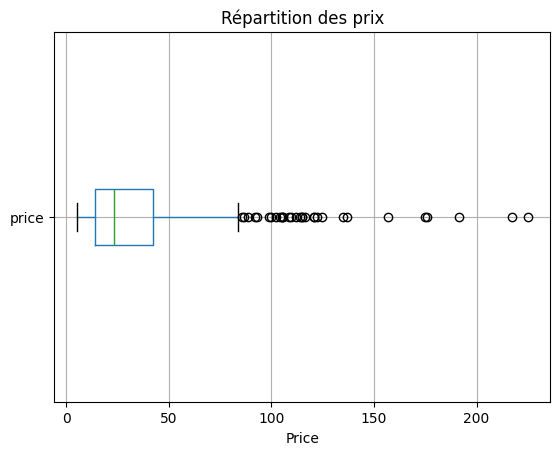

In [85]:
#Création d'une boîte à moustache de la répartition des prix grâce à Pandas
df_final.boxplot(column="price",vert=False)
plt.title("Répartition des prix")
plt.xlabel("Price")
plt.show()

La boite: Q1: 25% des produits coûtent moins de 15€, soit 1 produit sur 4 est vendu à moins de 15€. La médiane: 50% des produits coûtent moins de 25€
C'est le prix "du milieu". Q3: 75% des produits coûtent moins de 45€ soit 1 produit sur 4. La moustache à droite: C'est la limite au-delà de laquelle un prix est considéré comme "normal", tout ce qui dépasse 90€ est un outlier. La grande majorité des prix (75%) se situent entre 0€ et 45€, mais il existe des produits bien plus chers allant jusqu'à 225€, qui sont statistiquement exceptionnels dans ce jeu de données.
La médiane est proche de 0 donc 50% des produits ont un prix très bas.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2 - Exploration par l'utilisation de méthodes statistiques</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.1 - Identification par le Z-index</h3>
</div>

In [86]:
#Calculer la moyenne du prix
moyenne_prix=df_final["price"].mean()
print("La moyenne du prix est:",moyenne_prix)
#Calculer l'écart-type du prix
ecart_type_prix=df_final["price"].std()
print("L'écart type du prix est:",ecart_type_prix)
#Calcul du coefficient de variation
coef_var=df_final["price"].std()/df_final["price"].mean()
print("le coefficient de variation est:",coef_var)
#Calculer le Z-score
df_final["Z-Score"]=st.zscore(df_final["price"])

La moyenne du prix est: 32.33578431372549
L'écart type du prix est: 27.59583043211649
le coefficient de variation est: 0.8534145998865708


In [87]:
# Affichage du Z-Score
print(df_final["Z-Score"])
#Z> 3 prix anormalement élevé (outlier haut)
#Z< -3 prix anormalement bas (outlier bas)

0     -0.860725
1      0.314188
2      0.241663
3      0.999555
4     -0.356673
         ...   
709    0.495502
710    1.423829
711    0.930655
712    0.930655
713    2.163589
Name: Z-Score, Length: 714, dtype: float64


In [88]:
#Quel est le seuil prix dont le z-score est supérieur à 3? Quel est le prix à partir duquel une valeur est considérée comme un outlier selon le Z-score > 3
outliers=df_final[df_final["Z-Score"]>3] #filtrer les lignes ou Z_Score > à 3
seuil=outliers["price"].min() # Je prends le min parmis ces outliers
seuil

np.float64(116.4)

In [89]:
print("Nombre de produits outliers :", outliers.shape[0])

Nombre de produits outliers : 13


Les statistiques de base: prix moyen =32,33€, Ecart-type = 27,59€ (les prix s'éloignent en moyenne de 27,59€, la majorité des prix coutent entre 4,74€(32,33-27,59)et 59,92€(32,33+27,59) donc une forte dispersion, coef.variation= 0,85 (des prix hétérogènes à 85%, l'écart-type représente de la moyenne. Ces 13 produits sont statistiquement outliers mais pas forcément réellement aberrants. Sur 714 - 13 produits = 701 produits à prix "normaux" (Z-score entre -3 et +3) et 13 produits (Z-score > 3) dont les prix sont à vérifier avec une fourchette de prix haut(116€ - 222€) suggèrent qu'il pourraient s'agir d'une gammme premium et non d'erreurs de saisie. Z-score < -3: il n'y a pas de produits à prix anormalement bas. 

Le seuil de Z-score > 3 repose sur la règle empirique des distributions normales, selon laquelle 99,7% des valeurs se situent dans cet intervalle. Ainsi, les valeurs au-delà de ce seuil sont considérées comme extrêmement rares et potentiellement aberrantes. Toutefois, cette méthode suppose une distribution symétrique, ce qui n’est pas le cas ici, comme le montre le boxplot. Ce seuil doit être interprété avec prudence, c'est pourquoi, je le croise avec la méthode de l'IQR.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.2 - Identification par l'intervalle interquartile</h3>
</div>

In [90]:
#Utilisation de la fonction "describe" de Pandas pour l'étude des mesures de dispersion
df_final["price"].describe()

count    714.000000
mean      32.335784
std       27.595830
min        5.200000
25%       14.062500
50%       23.450000
75%       42.075000
max      225.000000
Name: price, dtype: float64

In [91]:
#Définir un seuil pour les articles "outliers" en prix
Q1=14.06
Q3=42.07
IQR=Q3-Q1
print("Interquartile = :",IQR)
#Seuil supérieur:
seuil_outliers=Q3+1.5*IQR
print("Seuil des valeurs outliers(IQR) est de:",seuil_outliers)

Interquartile = : 28.009999999999998
Seuil des valeurs outliers(IQR) est de: 84.08500000000001


In [92]:
#Définir le nombre d'articles et la proportion de l'ensemble du catalogue "outliers" - Combien de produits ont un prix anormal ET ça représente combien % du catalogue
outliers=df_final[df_final["price"]>seuil_outliers]
nbre_outliers=outliers.shape[0]
print("Le nombre d'outliers est de:",nbre_outliers)
Total_articles=df_final.shape[0]
proportion_outliers=nbre_outliers/Total_articles*100
print(f"La proportion des outliers du catalogue est de:{proportion_outliers:.2f}%") #31 articles identifiés comme outliers, soit 4,34% de l'ensemble du catalogue. 

Le nombre d'outliers est de: 31
La proportion des outliers du catalogue est de:4.34%


In [93]:
#Selon vous, ces outliers sont-ils justifiés ? Comment le démontrer si cela est possible ?
#chercher la logique du prix de vente par rapport au prix d'achat
outliers["marge_tx"] = ((outliers["price"] - outliers["purchase_price"])/ outliers["purchase_price"]) * 100
outliers[["price", "purchase_price", "marge_tx"]].head(32)

,price,purchase_price,marge_tx
22,108.5,52.22,107.774799
23,104.0,46.71,122.650396
24,176.0,78.25,124.920128
33,157.0,69.08,127.272727
53,99.0,49.62,99.516324
54,105.0,56.42,86.104218
56,88.4,44.30,99.548533
86,115.0,56.45,103.720106
87,105.0,55.88,87.902649
88,109.6,53.80,103.717472


Marges cohérentes: produits plus chers → marges similaires → logique commerciale respectée.
L’analyse des outliers via le taux de marge montre que la majorité des produits présente des marges comprises entre 60% et 130%, ce qui est cohérent avec une stratégie commerciale classique. Cela suggère que les valeurs élevées de prix sont justifiées et correspondent à des produits à forte valeur ajoutée.

Conclusion générale: le boxplot donne une première lecture visuelle de la distribution des prix, une majorité de produits vendues entre 14€ et 42€. En appliquant Les 2 méthodes statistiques pour aller plus loin dans cette lecture visuelle, qui s'appuient sur le même boxplot mais avec des repèrent différents. Le Z-Score lit la dispersion de la distribution, à partir de la moyenne et de l'écart-type, le seuil d'anomalie est de 116€ et identifie 13 outliers. l'IQR, se base directement sur la boite, les bords Q1 et Q3 définissent un seuil à 84€ et identifie les 31 outliers. Les 2 méthodes ne donnent pas le même résultat. Le Z-Score suppose une distribution symétrique autour de la moyenne et l'IQR s'adate à une distribution asymétrique comme le montre le boxplot. Pour cela que je retiens cette méthode pour le jeu de données car plus réaliste. 

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Analyse univariée du CA, des quantités vendues, des stocks et de la marge ainsi qu'une analyse multivariée  </h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.1 - Analyse des ventes en CA</h3>
</div>

In [94]:
##############################
# Calculer le CA du site web #
##############################

#Créer une colonne calculant le CA par article
df_final["ca_par_article"] = df_final["price"] * df_final["total_sales"]
#Calculer la somme de la colonne "ca_par_article"
#Ce résultat correspond au chiffre d'affaire du site web
ca_total = df_final["ca_par_article"].sum()
print(f"Le chiffre d'affaires du site web est de:{ca_total}€")

Le chiffre d'affaires du site web est de:143745.4€


In [95]:
###############################
# Palmarès des articles en CA #
###############################

#Effectuer le tri dans l'ordre décroissant du CA du dataset df_merge
df_final = df_final.sort_values(by="ca_par_article", ascending=False)#Classement des articles du CA du plus grand au plus petit
#Réinitialiser l'index du dataset par un reset_index
df_final = df_final.reset_index(drop=True)#repartir sur un df propre avec réinitialisation de l'index
#Afficher les 20 premiers articles en CA
df_final.head(20)

,id_web,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,sku,total_sales,post_date,post_date_gmt,product_type,post_title,post_excerpt,comment_status,post_modified,post_modified_gmt,guid,Z-Score,ca_par_article
0,15940.0,4352,1,225.0,0,outofstock,137.81,15940.0,11.0,2018-03-02 10:30:04,2018-03-02 09:30:04,Champagne,Champagne Egly-Ouriet Grand Cru Millésimé 2008,Issu d’un assemblage de 70% de Pinot Noir du g...,closed,2020-03-07 11:18:45,2020-03-07 10:18:45,https://www.bottle-neck.fr/?post_type=product&...,6.986536,2475.0
1,14983.0,5892,1,191.3,98,instock,116.06,14983.0,6.0,2019-03-28 10:21:36,2019-03-28 09:21:36,Champagne,Coteaux Champenois Egly-Ouriet Ambonnay Rouge ...,Cet Ambonnay évoque les grands Pinots Noirs de...,closed,2020-04-01 09:30:09,2020-04-01 07:30:09,https://www.bottle-neck.fr/?post_type=product&...,5.764481,1147.8
2,12587.0,4353,1,79.5,127,instock,45.91,12587.0,14.0,2018-03-02 10:37:26,2018-03-02 09:37:26,Champagne,Champagne Egly-Ouriet Grand Cru Brut Rosé,&nbsp;\n\nLe Rosé Grand Cru de la maison Egly-...,closed,2020-08-22 11:45:02,2020-08-22 09:45:02,https://www.bottle-neck.fr/?post_type=product&...,1.710305,1113.0
3,15325.0,5826,1,41.2,34,instock,21.71,15325.0,20.0,2019-03-27 17:59:49,2019-03-27 16:59:49,Vin,Agnès Levet Côte Rôtie Améthyste 2017,"<span style=""float: none;background-color: tra...",closed,2020-05-21 14:00:02,2020-05-21 12:00:02,https://www.bottle-neck.fr/?post_type=product&...,0.321441,824.0
4,13996.0,6212,1,115.0,16,instock,59.42,13996.0,7.0,2019-07-25 09:09:17,2019-07-25 07:09:17,Vin,Domaine des Comtes Lafon Volnay 1er Cru Santen...,"""Il s'agit là de la meilleure partie de l'appe...",closed,2020-06-16 09:30:16,2020-06-16 07:30:16,https://www.bottle-neck.fr/?post_type=product&...,2.997633,805.0
5,13913.0,5026,1,86.8,101,instock,50.13,13913.0,9.0,2018-07-18 10:46:30,2018-07-18 08:46:30,Champagne,Champagne Agrapart &amp; Fils Minéral Extra Br...,"Légèrement praliné au nez, nerveux, frais, inc...",closed,2020-05-11 14:35:02,2020-05-11 12:35:02,https://www.bottle-neck.fr/?post_type=product&...,1.975023,781.2
6,11602.0,5008,1,105.0,12,instock,56.42,11602.0,7.0,2018-07-17 10:52:41,2018-07-17 08:52:41,Vin,Domaine des Comtes Lafon Volnay 1er Cru Santen...,"""Il s'agit là de la meilleure partie de l'appe...",closed,2020-06-23 15:35:02,2020-06-23 13:35:02,https://www.bottle-neck.fr/?post_type=product&...,2.635005,735.0
7,15185.0,5767,1,175.0,12,instock,90.42,15185.0,4.0,2019-03-13 14:43:22,2019-03-13 13:43:22,Vin,Camille Giroud Clos de Vougeot 2016,<div>Ce vin provient de vignes âgées de 50 ans...,closed,2020-06-11 15:25:04,2020-06-11 13:25:04,https://www.bottle-neck.fr/?post_type=product&...,5.173398,700.0
8,14923.0,6126,1,135.0,138,instock,80.33,14923.0,5.0,2019-06-28 17:22:27,2019-06-28 15:22:27,Champagne,Champagne Gosset Célébris Vintage 2007,Une robe somptueuse a la teinte jaune pâle eti...,closed,2020-08-27 11:45:02,2020-08-27 09:45:02,https://www.bottle-neck.fr/?post_type=product&...,3.722888,675.0
9,13914.0,5025,1,112.0,136,instock,68.60,13914.0,6.0,2018-07-18 10:39:43,2018-07-18 08:39:43,Champagne,Champagne Agrapart &amp; Fils L'Avizoise Extra...,"Une cuvée surprenante, par son amer articulé a...",closed,2020-07-09 17:05:02,2020-07-09 15:05:02,https://www.bottle-neck.fr/?post_type=product&...,2.888844,672.0


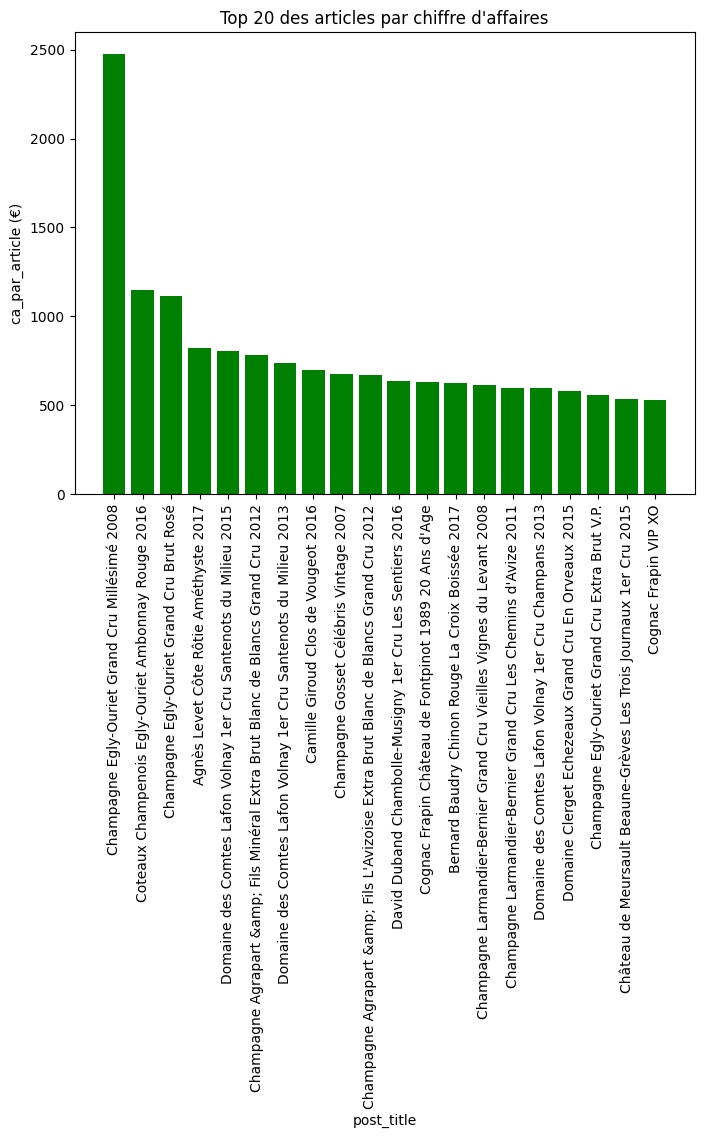

In [96]:
#Graphique en barre des 20 premiers articles avec plotly express
top20_ca = df_final.head(20)
plt.figure(figsize=(8,6))
plt.bar(top20_ca["post_title"].astype(str), top20_ca["ca_par_article"], color="green", linewidth=0.5)
plt.title("Top 20 des articles par chiffre d'affaires")
plt.xlabel("post_title")
plt.ylabel("ca_par_article (€)")
plt.xticks(rotation=90)
plt.show()

In [97]:
#############################
# Calculer le 20 / 80 en CA # 
#############################

#Créer une colonne calculant la part du CA de la ligne dans le dataset
df_final["part_ca"]=df_final["ca_par_article"]/ca_total
#Créer une colonne réalisant la somme cumulative de la colonne précedemment créée
df_final = df_final.sort_values(by="part_ca", ascending=False).reset_index(drop=True)
df_final["part_ca_cumulee"] = df_final["part_ca"].cumsum()
#Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% du CA
seuil=0.8
index_80 = df_final[df_final["part_ca_cumulee"] >= seuil].index[0]
nb_articles_80 = index_80 + 1
print(f"Nombre d'articles représentant 80 % du CA : {nb_articles_80}")

Nombre d'articles représentant 80 % du CA : 435


In [98]:
#Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web
total_articles=df_final.shape[0]# afficher le nombre total des articles
propotion_articles=nb_articles_80/total_articles*100
print(f"Ces {nb_articles_80} articles représentent {propotion_articles:.2f}% du catalogue entier du site web.")

Ces 435 articles représentent 60.92% du catalogue entier du site web.


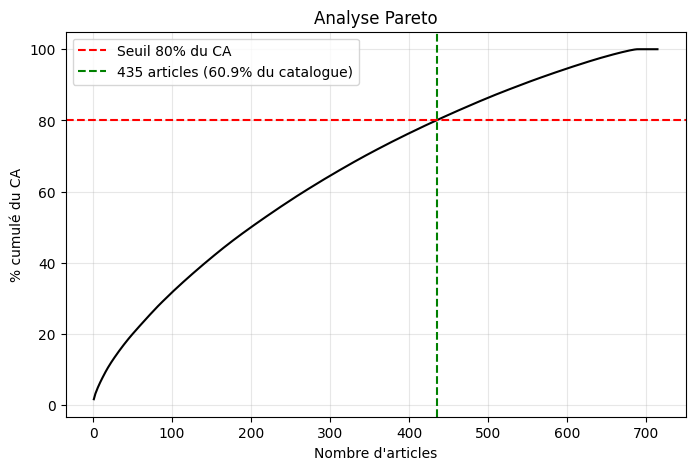

In [99]:
plt.figure(figsize=(8, 5))
x = np.arange(1, len(df_final) + 1)

plt.plot(x, df_final["part_ca_cumulee"] * 100, color="black")
plt.axhline(80, color="red", linestyle="--", label="Seuil 80% du CA")
plt.axvline(nb_articles_80, color="green", linestyle="--",
            label=f"{nb_articles_80} articles ({propotion_articles:.1f}% du catalogue)")

plt.xlabel("Nombre d'articles")
plt.ylabel("% cumulé du CA")
plt.title("Analyse Pareto")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Cette répartition ne correspond pas à une règle 20/80 stricte,le CA n’est pas concentré sur une minorité d’articles. La une distribution est plutôt équilibrée. Plus de la moitié des produits contribuent majoritairement au CA, ce qui montre une certaine diversité dans les articles qui performent bien. Le reste du catalogue, qui représente 47,5 % des articles, ne génère que 20 % du CA, ce qui peut pointer vers des références moins vendues ou moins rentables.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.2 - Analyse des ventes en quantité</h3>
</div>

In [100]:
#####################################
# Palmarès des articles en quantité #
#####################################

#Effectuer le tri dans l'ordre décroissant de quantités vendues du dataset df_merge
df_final=df_final.sort_values(by="total_sales",ascending=False)
#Réinitialiser l'index du dataset par un reset_index
df_final=df_final.reset_index(drop=True)
#Afficher les 20 premiers articles en quantité
df_final.head(20)

,id_web,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,sku,total_sales,post_date,...,post_title,post_excerpt,comment_status,post_modified,post_modified_gmt,guid,Z-Score,ca_par_article,part_ca,part_ca_cumulee
0,16148.0,4867,1,9.9,121,instock,4.86,16148.0,36.0,2018-05-03 13:20:05,...,Château De La Selve IGP Coteaux de l'Ardèche M...,"<div>\n\nUn rosé minéral, fruité et d’une gran...",closed,2020-08-27 09:30:15,2020-08-27 07:30:15,https://www.bottle-neck.fr/?post_type=product&...,-0.813583,356.4,0.002479,0.227890
1,15415.0,4203,1,9.9,74,instock,5.01,15415.0,27.0,2018-02-15 14:33:42,...,Mas Laval IGP Pays d'Hérault Les Pampres Blanc...,Vin de gourmandise à boire sur la fraîcheur po...,closed,2020-07-11 16:45:03,2020-07-11 14:45:03,https://www.bottle-neck.fr/?post_type=product&...,-0.813583,267.3,0.001860,0.404114
2,14864.0,4275,1,14.9,62,instock,7.78,14864.0,24.0,2018-02-27 13:33:54,...,I Fabbri Chianti Classico Lamole 2017,Un nez typique de petits fruits rouges. Une bo...,closed,2020-08-22 14:35:02,2020-08-22 12:35:02,https://www.bottle-neck.fr/?post_type=product&...,-0.632270,357.6,0.002488,0.215478
3,14950.0,4726,1,12.7,0,outofstock,6.82,14950.0,22.0,2018-04-18 11:53:51,...,François Baur Pinot Noir Schlittweg 2017,"Un éclat de fruits, de la souplesse, de la ron...",closed,2020-05-06 11:35:01,2020-05-06 09:35:01,https://www.bottle-neck.fr/?post_type=product&...,-0.712048,279.4,0.001944,0.367906
4,16525.0,4647,1,28.5,45,instock,14.14,16525.0,22.0,2018-04-17 09:28:58,...,Bernard Baudry Chinon Rouge La Croix Boissée 2017,"Sur ce sol très calcaire, la Croix Boissée dél...",closed,2020-07-31 09:31:39,2020-07-31 07:31:39,https://www.bottle-neck.fr/?post_type=product&...,-0.139096,627.0,0.004362,0.082205
5,14570.0,6129,1,5.2,68,instock,2.74,14570.0,20.0,2019-06-28 18:01:06,...,Moulin de Gassac IGP Pays d'Hérault Guilhem Bl...,Nez Séduisant et puissant. Bouquet de fleurs j...,closed,2020-08-26 15:55:02,2020-08-26 13:55:02,https://www.bottle-neck.fr/?post_type=product&...,-0.984018,104.0,0.000724,0.953443
6,15325.0,5826,1,41.2,34,instock,21.71,15325.0,20.0,2019-03-27 17:59:49,...,Agnès Levet Côte Rôtie Améthyste 2017,"<span style=""float: none;background-color: tra...",closed,2020-05-21 14:00:02,2020-05-21 12:00:02,https://www.bottle-neck.fr/?post_type=product&...,0.321441,824.0,0.005732,0.038678
7,15758.0,4220,1,11.6,48,instock,5.75,15758.0,18.0,2018-02-16 10:54:27,...,Xavier Frissant Touraine Amboise Chenin Les Pi...,"Un Touraine Amboise fin et élégant, un joli ch...",closed,2020-08-27 11:45:02,2020-08-27 09:45:02,https://www.bottle-neck.fr/?post_type=product&...,-0.751937,208.8,0.001453,0.579126
8,13572.0,5803,1,17.1,47,instock,9.19,13572.0,17.0,2019-03-19 11:33:39,...,Château Tour Haut-Caussan Médoc 2015,Vous trouverez dans cette cuvée du Château Tou...,closed,2020-08-26 16:55:02,2020-08-26 14:55:02,https://www.bottle-neck.fr/?post_type=product&...,-0.552492,290.7,0.002022,0.340116
9,15561.0,5778,1,5.8,44,instock,3.09,15561.0,17.0,2019-03-15 10:20:59,...,Maurel Pays d'Oc Merlot 2018,<div>Robe rouge rubis avec des reflets violine...,closed,2020-08-14 10:55:02,2020-08-14 08:55:02,https://www.bottle-neck.fr/?post_type=product&...,-0.962261,98.6,0.000686,0.967539


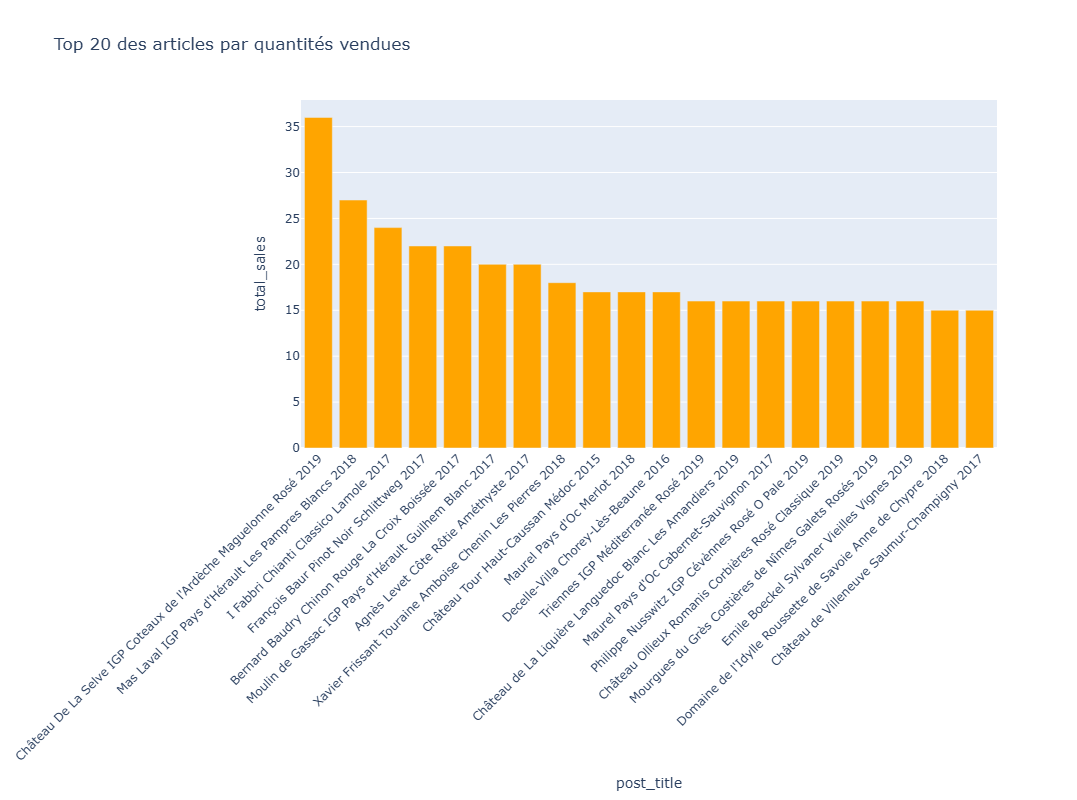

In [101]:
top20 = df_final.head(20)
fig = px.bar(top20, x="post_title", y="total_sales", 
    title="Top 20 des articles par quantités vendues",
    color_discrete_sequence=["orange"])
fig.update_layout(
    height=800,   # graphique plus grand en hauteur
    width=1000,
    margin=dict(b=280),
    xaxis_tickangle=-45,
)
fig.show()

In [102]:
#############################
# Calculer le 20 / 80 en CA #
#############################

#Créer une colonne calculant la part en quantité de la ligne dans le dataset
df_final["part_quantite"] = df_final["total_sales"] / df_final["total_sales"].sum()
#Créer une colonne réalisant la somme cumulative de la colonne précedemment créée
df_final=df_final.sort_values(by="part_quantite",ascending=False).reset_index(drop=True)
df_final["part_quantite_cumulee"] = df_final["part_quantite"].cumsum()
#Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% des ventes en quantité
seuil_ventes=0.8
index_ventes_80=df_final[df_final["part_quantite_cumulee"]>=seuil_ventes].index[0]
qte_articles_80=index_ventes_80+1
print(f"Nombre d'articles représentant 80% de ventes en quantité:{qte_articles_80}")
#Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web
total_articles=df_final.shape[0]
proportion_quantite=qte_articles_80/total_articles*100
print(f"Nombre total d'articles dans le catalogue : {total_articles}")
print(f"Ces {qte_articles_80} articles représentent {proportion_quantite:.2f}% du catalogue entier du site web.")

Nombre d'articles représentant 80% de ventes en quantité:434
Nombre total d'articles dans le catalogue : 714
Ces 434 articles représentent 60.78% du catalogue entier du site web.


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.3 - Analyse des stocks</h3>
</div>

In [103]:
######################################
# Calculer le nombre de mois de stock #
######################################

#Création de la colonne Rotation de stock
df_final["rotation_stock"]=np.where(df_final["stock_quantity"]>0,df_final["total_sales"]/df_final["stock_quantity"],np.nan)
#Remplacement des "inf" par 0
df_final["rotation_stock"]=df_final["rotation_stock"].fillna(0)#Je remplace les NaN en 0
#Effectuer le tri dans l'ordre décroissant du nombre de mois de stock dans le dataset df_merge
df_final["mois_stock"]=np.where(df_final["rotation_stock"]>0,1/df_final["rotation_stock"],np.nan)
df_final=df_final.sort_values(by="mois_stock",ascending=False)
#mettre nombre mois de stock: valorisation/par CA mensuel

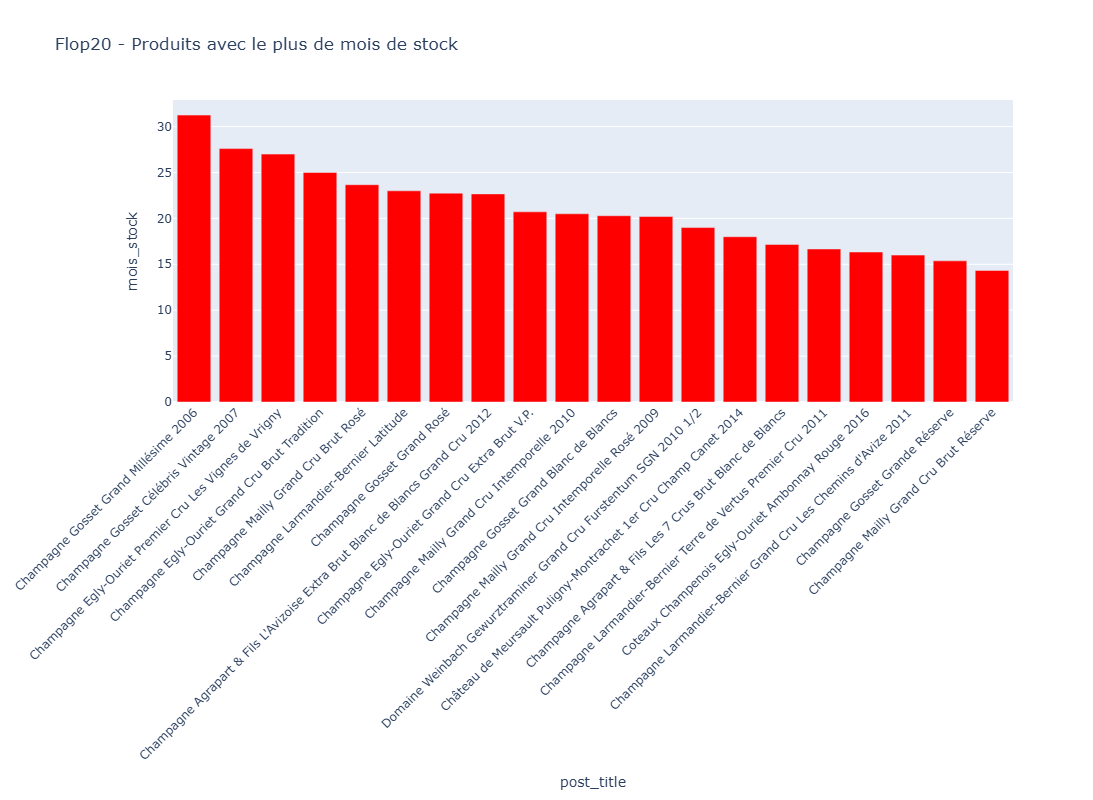

In [104]:
#Graphique en barre du flop 20 des produits qui ont le plus de mois de stock
flop20=df_final.head(20).reset_index(drop=True)
fig=px.bar(flop20,
x="post_title",
y="mois_stock",
title="Flop20 - Produits avec le plus de mois de stock",
color_discrete_sequence=["red"])
fig.update_layout(
    height=800,   # graphique plus grand en hauteur
    width=1000,
    margin=dict(b=280),
    xaxis_tickangle=-45,
)
fig.show()

Si on continue à vendre certains produit au même rythme, le stock actuel mettra 20 à 30 mois à s'écouler. Ces produits montent très haut car se vendent très lentement, soit le stock est très élevé, soit les ventes sont quasi nulles.
sur ce graphique on voit que les produits tournent mal, stocks surdimensionnées, risque d'obsolescence et d'immobilisation financière.
mois_stock= projection mathématique basée sur la vitesse de vente actuelle

In [105]:
####################################
# Valorisation des stocks en euros #
####################################

#Création de la colonne Valorisation des stocks en euros
df_final["valorisation_stock"]=df_final["stock_quantity"]*df_final["price"]
#Calculer la somme de la colonne "Valorisation_stock_euros"
valeur_stock=df_final["valorisation_stock"].sum()
print(f"Valeur total du stock(€):{valeur_stock:.2f}€")

Valeur total du stock(€):494433.90€


In [106]:
##############################################
# Valorisation du nombre de produits en stock #
##############################################

#Calculer la somme de la colonne stock quantity
produits_stock=df_final["stock_quantity"].sum()
print(f"Nombre total de produits en stock:{produits_stock}")

Nombre total de produits en stock:16731


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.4 - Analyse du taux de marge</h3>
</div>

In [107]:
############################
# Analyse du taux de marge #
############################

#Création de la colonne Prix HT
taux_tva=0.20
df_final["prix_ht"]=df_final["price"]/(1+taux_tva)
#Création de la colonne Taux de marge
df_final["taux_marge"]=(df_final["prix_ht"]-df_final["purchase_price"])/df_final["prix_ht"]
#Afficher le prix minimum de la colonne "taux_marge"
taux_min=df_final["taux_marge"].min()
ligne_min=df_final[df_final["taux_marge"]==taux_min]
prix_min=ligne_min["price"].values[0]
print(f"prix correspondant au taux de marge minimum:{prix_min} €")
#Afficher le prix maximum de la colonne "taux_marge"
taux_max=df_final["taux_marge"].max()
ligne_max=df_final[df_final["taux_marge"]==taux_max]
prix_max=ligne_max["price"].values[0]
print(f"prix correspondant au taux de marge maximum:{prix_max} €")

prix correspondant au taux de marge minimum:12.65 €
prix correspondant au taux de marge maximum:62.5 €


In [108]:
#Affichage de la ligne avec un taux de marge inférieur à 0
lignes_negatives= df_final[df_final["taux_marge"] < 0]
print((df_final["taux_marge"]<0).sum())

1


In [109]:
lignes_negatives

,id_web,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,sku,total_sales,post_date,...,ca_par_article,part_ca,part_ca_cumulee,part_quantite,part_quantite_cumulee,rotation_stock,mois_stock,valorisation_stock,prix_ht,taux_marge
694,12589.0,4355,0,12.65,97,instock,77.48,12589.0,0.0,2018-03-02 10:46:10,...,0.0,0.0,1.0,0.0,1.0,0.0,NaN,1227.05,10.541667,-6.349881


La ligne avec le taux de marge négatif: il doit s'agir d'une erreur de saisie, on voit vente à 12,65 et prix d'achat à 77,48. Pas d'inpact réel car produit non vendu, total sales = 0 sinon perte estimé à 97*77,48= 7515,56 euros

In [110]:
#Création d'un dataframe avec les taux positifs
taux_positifs=df_final[df_final["taux_marge"]>0]
#Afficher le prix minimum de la colonne "taux_marge"
#Afficher le prix minimum de la colonne "taux_marge"
prix_min = taux_positifs.loc[taux_positifs["taux_marge"].idxmin(), "price"]
print(f"Prix correspondant au taux de marge positif minimum:{prix_min} €")
#Afficher le prix maximum de la colonne "taux_marge"
prix_max = taux_positifs.loc[taux_positifs["taux_marge"].idxmax(), "price"]
print(f"Prix correspondant au taux de marge positif maximum:{prix_max} €")

Prix correspondant au taux de marge positif minimum:13.1 €
Prix correspondant au taux de marge positif maximum:62.5 €


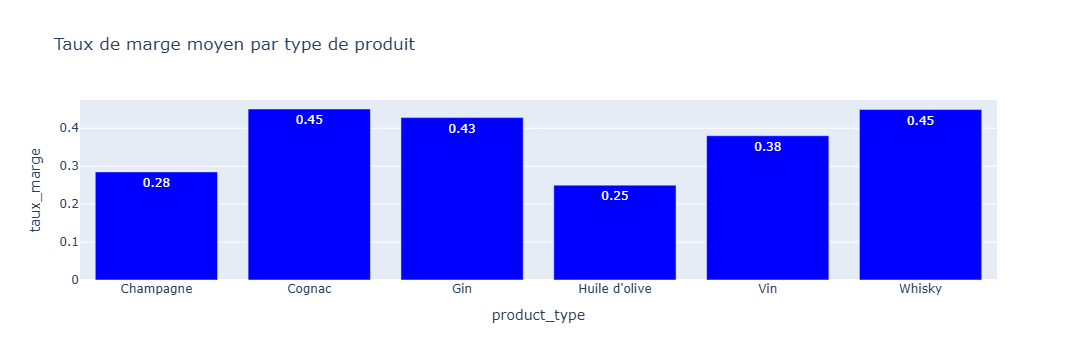

In [111]:
#Création d'un dataframe avec le taux de marge moyen par type de produit
taux_marge_moyen=taux_positifs.groupby("product_type")["taux_marge"].mean().reset_index()
#Affichage dans un graphique du taux de marge par type de produit
fig=px.bar(taux_marge_moyen,
x="product_type",
y="taux_marge",
title="Taux de marge moyen par type de produit",
text_auto=".2f")
fig.update_traces(marker_color="blue")
fig.show()

Sur ce graphique, on observe le taux de marge moyen par type de produit.
Ce qu’il faut retenir, c’est que tous les produits ne contribuent pas de la même manière à la rentabilité.
D’abord, on voit que le Whisky et le Cognac affichent les taux de marge les plus élevés, autour de 0,45.
Ce sont clairement les produits les plus rentables, ceux qui génèrent le plus de marge pour l’entreprise.
Juste derrière, on retrouve le Gin et le Vin, avec des marges intermédiaires, autour de 0,38 à 0,43.
Ce sont des produits qui restent intéressants, mais moins stratégiques que le Whisky ou le Cognac.
Ensuite, l’huile d’olive présente une marge plus faible, autour de 0,25.
Elle reste rentable, mais beaucoup moins que les alcools premium.
Même constate pour le Champagne un taux de marge d’environ 0,28.
Huile d'olive et champagbe: marge les plus faibles, mais niveau cohérent avec l'activité. 
Point important: Une valeur extrême peut fortement déséquilibrer la moyenne, c'est la raison pour laquelle les données négatives ont été exlus du calcul du taux de marge moyen spécifiquement la ligne 700 product_id 4355

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.5 - Analyse des corrélations entre les variables stock, sales et price</h3>
</div>

In [112]:
#Que peut-on conclure des corrélations ?

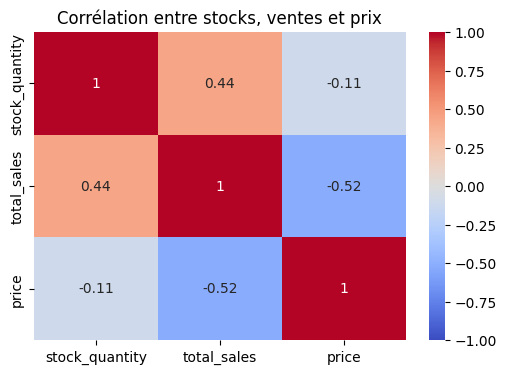

In [113]:
############################
# Analyse des corrélations #
############################

#Création d'une heatmap de corrélation avec les variables stock, sales et price
relations=df_final[["stock_quantity", "total_sales","price"]]
corr=relations.corr()
plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Corrélation entre stocks, ventes et prix')
plt.show()

### Interprétation des résultats
la correlation stock_quantity et total_sales est positive mais modéré: 0.44 plus un produit est vendu, plus il a de stock
la correlation total_sales et price est négative et modéré: - 0.52 plus un article est cher, moins il se vend.
Quasiment pas de corrélation entre stock_quantity et price: - 0.11 le niveau de stock d'un produit ne dépend quasiment pas de son prix
le prix n'est pas un facteur qui justifie le niveau de stock.

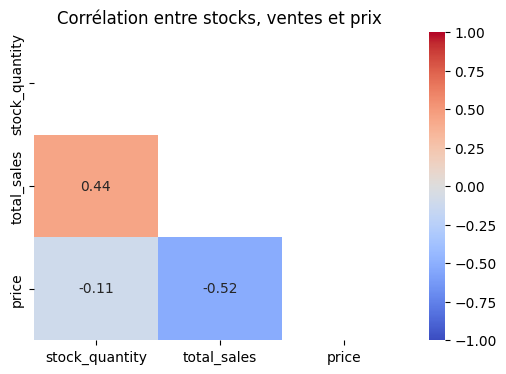

In [114]:
#On peut également créer un mask pour n'afficher qu'une demi heatmap
relations = df_final[["stock_quantity", "total_sales", "price"]]
corr = relations.corr()
# Mask du triangle supérieur
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, mask=mask)
plt.title('Corrélation entre stocks, ventes et prix')
plt.show()

L'utilisation du mask permet d'éviter la redondance d'affichage des informations. On peut dès lors se concentrer sur les données essentielles. 

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.6 - Mise à disposition de la nouvelle table sur un fichier Excel</h3>
</div>

In [115]:
#Mettre le dataset df_merge sur un fichier Excel
#Cette étape peut être utile pour partager le résultat du dataset obtenu avec les équipes.  
df_final.to_excel("Zootyam_Michelle_3_Df_final_042026.xlsx", index=False)